In [52]:
import numpy as np    # numerical python
import matplotlib     # matrix plotting library
import matplotlib.pyplot # python plotting
import skimage as sk  # sci-kit image
import skimage.io as skio # input/output
import scipy          # scientific python
import cv2            # opencv

import lib
import align_image_code

In [53]:
def make_gaussian(sigma):
    ksize=int(np.ceil(sigma*3)//2*2+1)
    g=cv2.getGaussianKernel(ksize,sigma)
    g_T=np.transpose(g)
    g_filter=np.ma.outer(g,g_T)
    return g_filter

In [54]:
def make_hybrid(im1, im2, lowpass_sigma, highpass_sigma, alpha=1):
    lowpass_g_filter = make_gaussian(lowpass_sigma)
    im1_lowpass = scipy.signal.convolve2d(im1, lowpass_g_filter, mode='same', boundary='wrap')
    highpass_g_filter = make_gaussian(highpass_sigma)
    im2_highpass = im2 - scipy.signal.convolve2d(im2, highpass_g_filter, mode='same', boundary='wrap')
    im_hybrid = im1_lowpass + im2_highpass * alpha
    im_hybrid = np.where(im_hybrid > 1.0, 1.0, im_hybrid)
    im_hybrid = sk.img_as_ubyte(im_hybrid)
    return im_hybrid

Please select 2 points in each image for alignment.


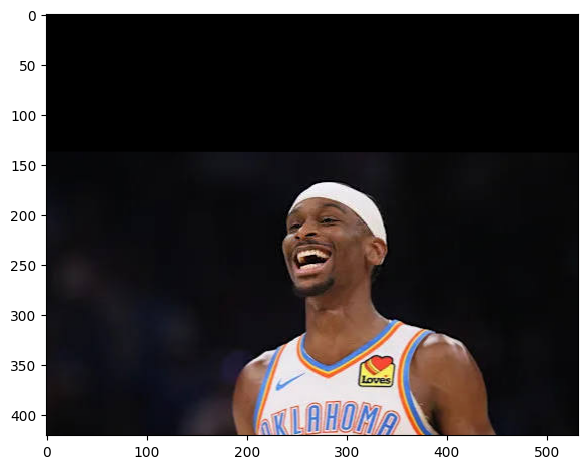

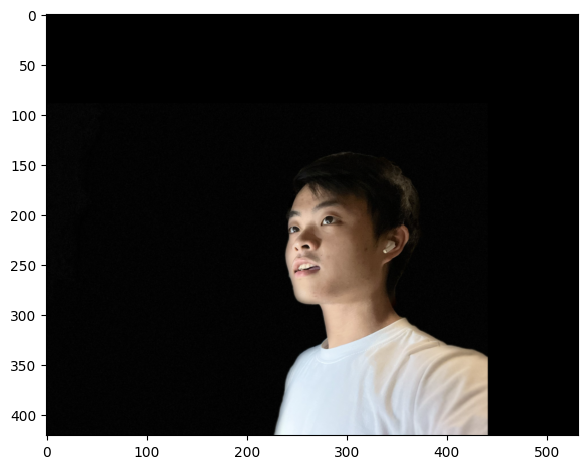

In [55]:
im1name = 'data/sga.png'
im2name = 'data/chiahan.png'

# 1. 讀取圖片，只取前 3 個通道 (去掉 PNG 的透明通道 Alpha)，並轉成 0.0~1.0 的浮點數
im1 = sk.img_as_float(skio.imread(im1name)[:, :, :3])
im2 = sk.img_as_float(skio.imread(im2name)[:, :, :3])

# 2. 切換成彈出式視窗來點擊特徵點 (Mac 若 tk 報錯可改用 %matplotlib osx 或 %matplotlib qt)
%matplotlib tk
im1_aligned, im2_aligned = align_image_code.align_images(im1, im2)

# 3. 點完後切回 inline，讓結果直接顯示在 Notebook 網頁下方，並存檔備份
%matplotlib inline
skio.imshow(im1_aligned)
skio.show()

skio.imshow(im2_aligned)
skio.show()

im1_aligned=sk.color.rgb2gray(im1_aligned)
im2_aligned=sk.color.rgb2gray(im2_aligned)

# 強烈建議順便存檔，這樣後面調參數不用每次重選點！
lib.save_file('sga_aligned.png', im1_aligned)
lib.save_file('chiahan_aligned.png', im2_aligned)

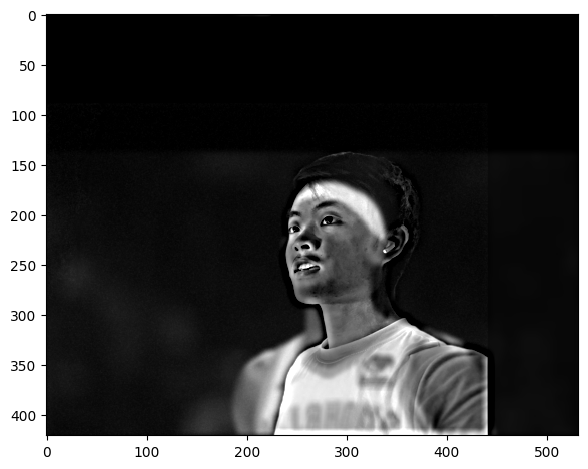

In [56]:
low_sigma=3.0
high_sigma=5.0
im_hybrid=make_hybrid(im1_aligned,im2_aligned,low_sigma,high_sigma,2)
skio.imshow(im_hybrid)
skio.show()
lib.save_file('John_sga_hybrid.png',im_hybrid/255.0)


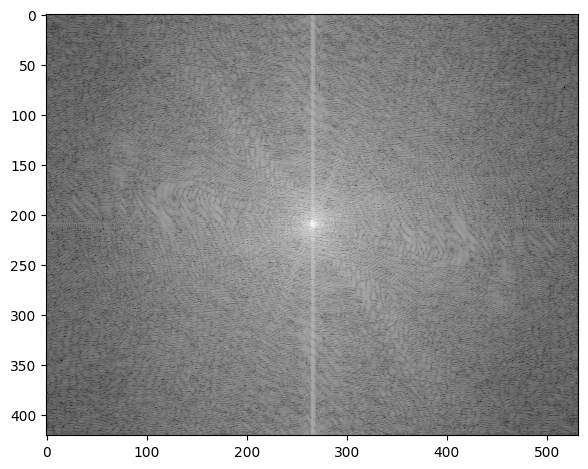

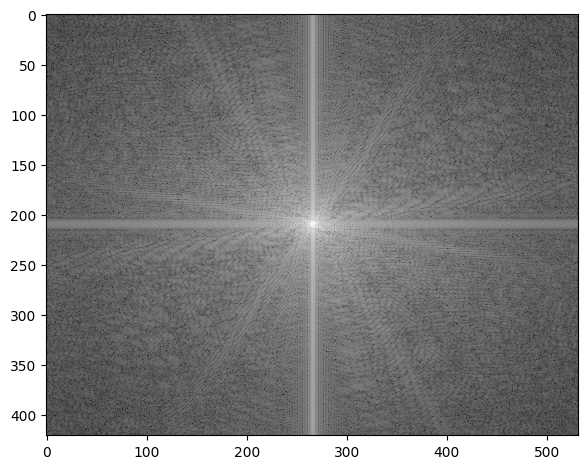

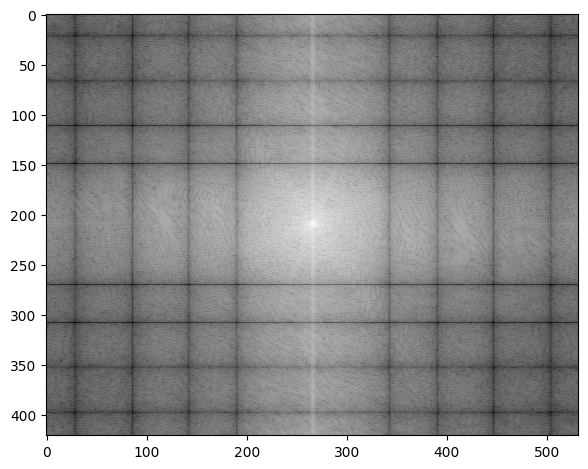

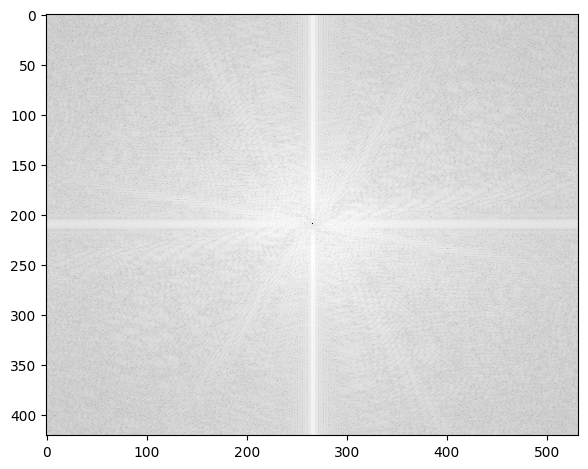

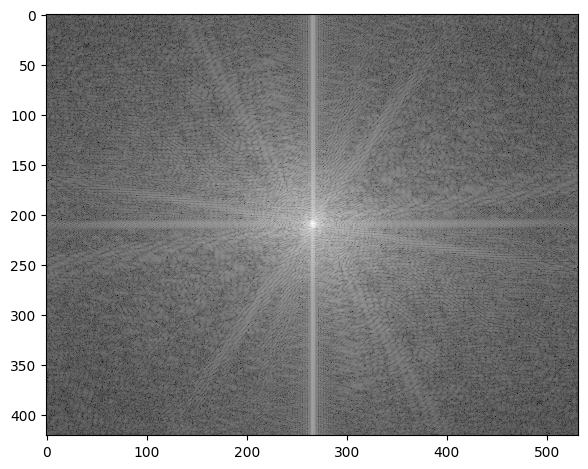

In [57]:
im1_aligned_freq=np.log(np.abs(np.fft.fftshift(np.fft.fft2(im1_aligned))))
im1_aligned_freq= (im1_aligned_freq - np.min(im1_aligned_freq))/np.ptp(im1_aligned_freq)
skio.imshow(im1_aligned_freq)
skio.show()
lib.save_file('im1_aligned_freq.png',im1_aligned_freq)

im2_aligned_freq=np.log(np.abs(np.fft.fftshift(np.fft.fft2(im2_aligned))))
im2_aligned_freq= (im2_aligned_freq - np.min(im2_aligned_freq))/np.ptp(im2_aligned_freq)
skio.imshow(im2_aligned_freq)
skio.show()
lib.save_file('im2_aligned.png',im2_aligned_freq)

lowpass_sigma=3.0
lowpass_g_filter = make_gaussian(lowpass_sigma)
im1_lowpass = scipy.signal.convolve2d(im1_aligned, lowpass_g_filter, mode='same', boundary='wrap')
im1_filtered_freq = np.log(np.abs(np.fft.fftshift(np.fft.fft2(im1_lowpass))))
im1_filtered_freq = (im1_filtered_freq - np.min(im1_filtered_freq))/np.ptp(im1_filtered_freq)
skio.imshow(im1_filtered_freq)
skio.show()
lib.save_file('im1_filter.png',im1_filtered_freq)

highpass_sigma=5.0
highpass_g_filter = make_gaussian(highpass_sigma)
im2_highpass = im2_aligned - scipy.signal.convolve2d(im2_aligned, highpass_g_filter, mode='same', boundary='wrap')
im2_filtered_freq = np.log(np.abs(np.fft.fftshift(np.fft.fft2(im2_highpass))))
im2_filtered_freq = (im2_filtered_freq - np.min(im2_filtered_freq))/np.ptp(im2_filtered_freq)
skio.imshow(im2_filtered_freq)
skio.show()
lib.save_file('im2_filter.png',im2_filtered_freq)

im_hybrid_freq = np.log(np.abs(np.fft.fftshift(np.fft.fft2(im_hybrid))))
im_hybrid_freq = (im_hybrid_freq - np.min(im_hybrid_freq))/np.ptp(im_hybrid_freq)
skio.imshow(im_hybrid_freq)
skio.show()
lib.save_file('hybrid_freq.png',im_hybrid_freq)